# RAG: Retrieval Augmented Generation (Vector)

In [2]:
# Document Structure

from langchain_core.documents import Document

#### RAG Short Notes

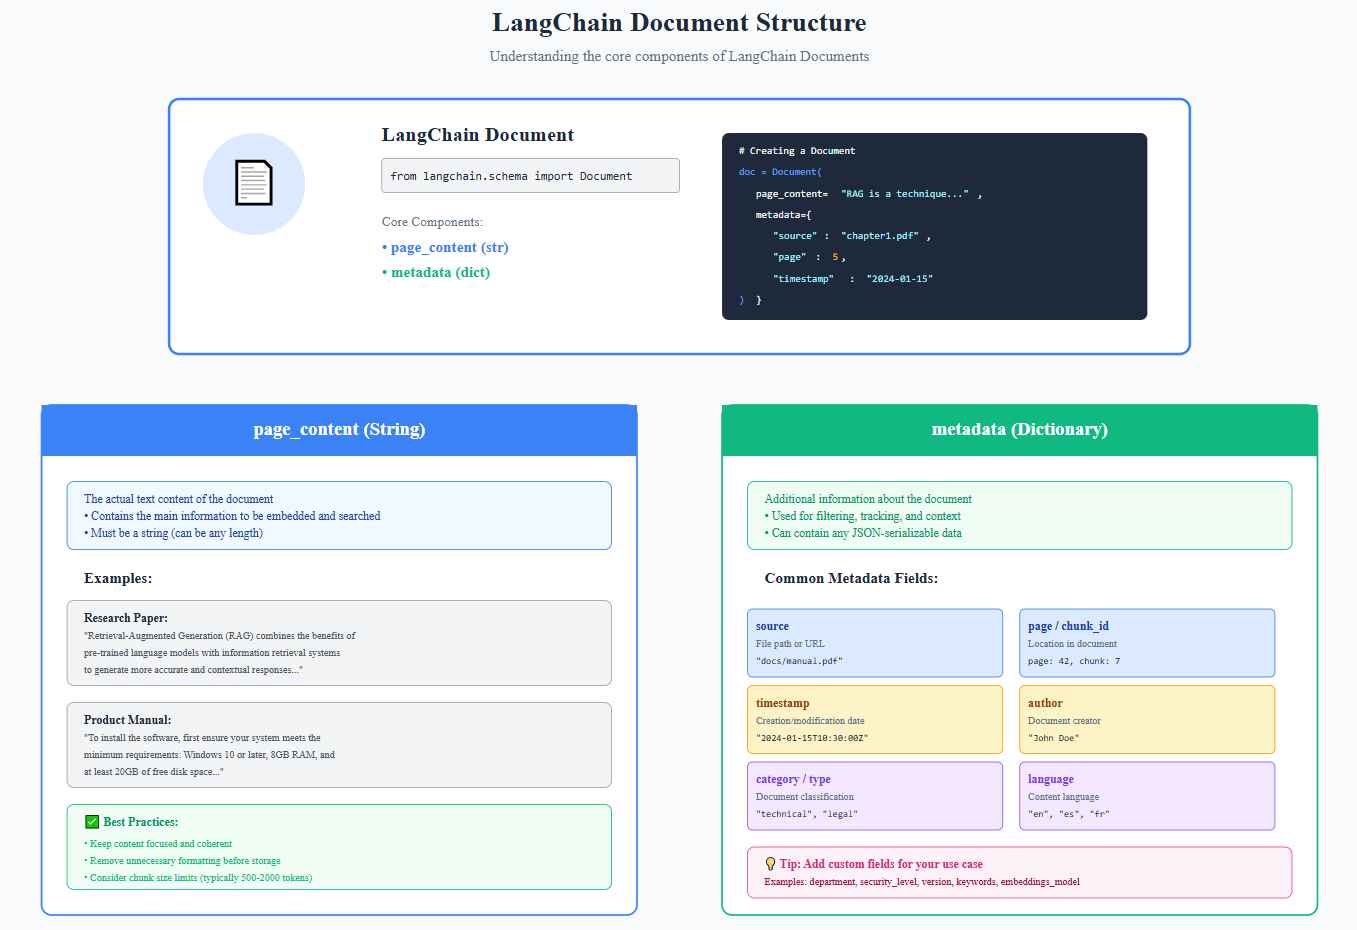

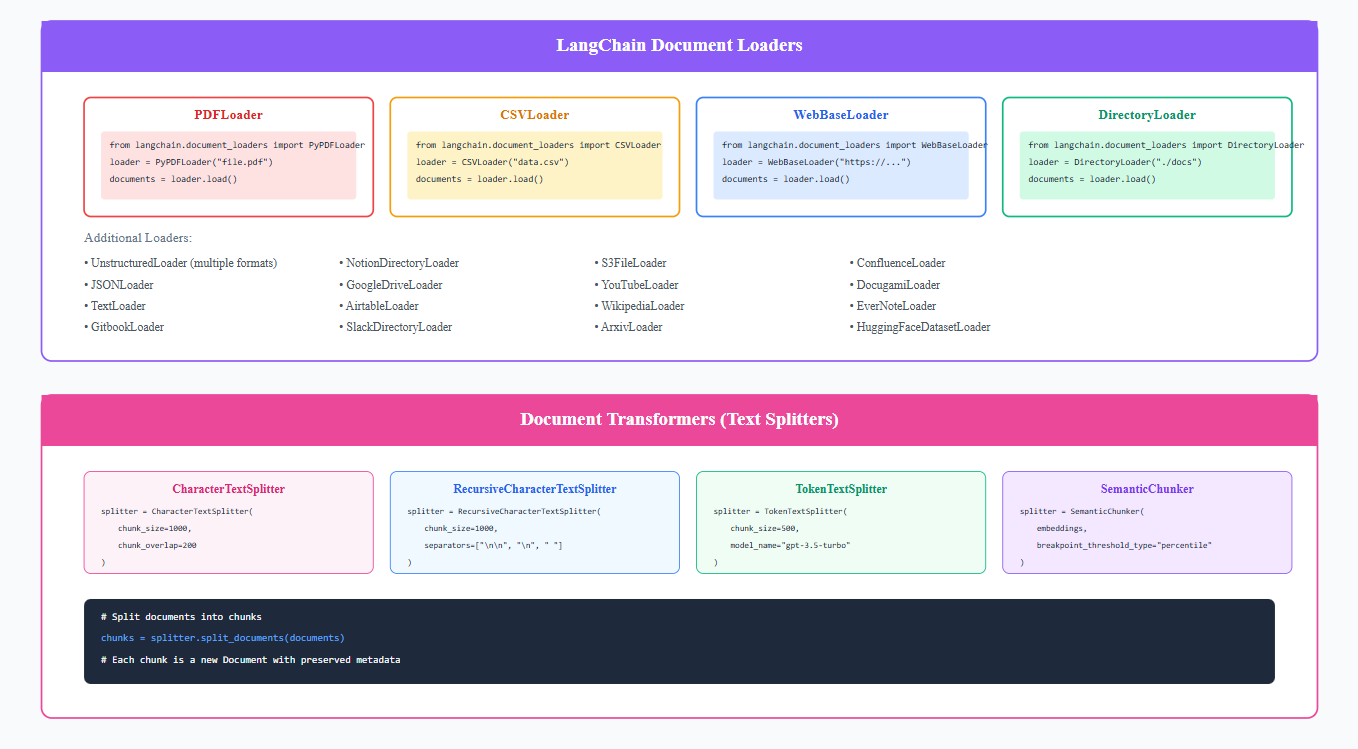

## 1. Data Ingestion Pipeline

### a) Data Ingestion

In [3]:
doc = Document(
    page_content="This is a sample text content that I am using to create RAG.",
    metadata={
        "source": "example.txt", 
        "pages": 1,
        "date_created": "2026-11-12",
        "author": "Saksham Raj"
    }
)

# Metadata plays a very important role in allowing to apply filters on the documents. 
# For example, you can filter documents based on the author or date created.
# This is useful when you have a large collection of documents and want to retrieve only those that match certain criteria.

doc

Document(metadata={'source': 'example.txt', 'pages': 1, 'date_created': '2026-11-12', 'author': 'Saksham Raj'}, page_content='This is a sample text content that I am using to create RAG.')

In [4]:
## Create a simple txt file
import os
os.makedirs("../data/text_files",exist_ok=True)

In [5]:
sample_texts={
    "../data/text_files/python_intro.txt":"""Python Programming Introduction

Python is a high-level, interpreted programming language known for its simplicity and readability.
Created by Guido van Rossum and first released in 1991, Python has become one of the most popular
programming languages in the world.

Key Features:
- Easy to learn and use
- Extensive standard library
- Cross-platform compatibility
- Strong community support

Python is widely used in web development, data science, artificial intelligence, and automation.""",
    
    "../data/text_files/machine_learning.txt": """Machine Learning Basics

Machine learning is a subset of artificial intelligence that enables systems to learn and improve
from experience without being explicitly programmed. It focuses on developing computer programs
that can access data and use it to learn for themselves.

Types of Machine Learning:
1. Supervised Learning: Learning with labeled data
2. Unsupervised Learning: Finding patterns in unlabeled data
3. Reinforcement Learning: Learning through rewards and penalties

Applications include image recognition, speech processing, and recommendation systems
    
    
    """

}

for filepath,content in sample_texts.items():
    with open(filepath,'w',encoding="utf-8") as f:
        f.write(content)

print("✅ Sample text files created!")

✅ Sample text files created!


In [ ]:
# TextLoader

from langchain_community.document_loaders import TextLoader

loader=TextLoader("../data/text_files/python_intro.txt",encoding="utf-8")
document=loader.load()
print(document)

[Document(metadata={'source': '../data/text_files/python_intro.txt'}, page_content='Python Programming Introduction\n\nPython is a high-level, interpreted programming language known for its simplicity and readability.\nCreated by Guido van Rossum and first released in 1991, Python has become one of the most popular\nprogramming languages in the world.\n\nKey Features:\n- Easy to learn and use\n- Extensive standard library\n- Cross-platform compatibility\n- Strong community support\n\nPython is widely used in web development, data science, artificial intelligence, and automation.')]


In [9]:
# Directory Loader
from langchain_community.document_loaders import DirectoryLoader

## load all the text files from the directory
dir_loader=DirectoryLoader(
    "../data/text_files",
    glob="**/*.txt", ## Pattern to match files  
    loader_cls= TextLoader, ##loader class to use
    loader_kwargs={'encoding': 'utf-8'},
    show_progress=False
)

documents=dir_loader.load()
documents

[Document(metadata={'source': '..\\data\\text_files\\machine_learning.txt'}, page_content='Machine Learning Basics\n\nMachine learning is a subset of artificial intelligence that enables systems to learn and improve\nfrom experience without being explicitly programmed. It focuses on developing computer programs\nthat can access data and use it to learn for themselves.\n\nTypes of Machine Learning:\n1. Supervised Learning: Learning with labeled data\n2. Unsupervised Learning: Finding patterns in unlabeled data\n3. Reinforcement Learning: Learning through rewards and penalties\n\nApplications include image recognition, speech processing, and recommendation systems\n\n\n    '),
 Document(metadata={'source': '..\\data\\text_files\\python_intro.txt'}, page_content='Python Programming Introduction\n\nPython is a high-level, interpreted programming language known for its simplicity and readability.\nCreated by Guido van Rossum and first released in 1991, Python has become one of the most popu

In [16]:
print(type(documents))

<class 'list'>


In [17]:
print(type(documents[0]))

<class 'langchain_core.documents.base.Document'>


In [ ]:
from langchain_community.document_loaders import PyPDFLoader, PyMuPDFLoader
from langchain_community.document_loaders import DirectoryLoader

## load all the PDF files from the directory
dir_loader=DirectoryLoader(
    "../data/pdf_files",
    glob="**/*.pdf", ## Pattern to match files  
    loader_cls= PyMuPDFLoader, ##loader class to use
    show_progress=False
)

pdf_documents=dir_loader.load()
pdf_documents

[Document(metadata={'producer': 'Acrobat Distiller 8.1.0 (Windows)', 'creator': 'Arbortext Advanced Print Publisher 11.0.3433/W Unicode', 'creationdate': '2021-01-20T00:00:16+05:30', 'source': '..\\data\\pdf_files\\attention.pdf', 'file_path': '..\\data\\pdf_files\\attention.pdf', 'total_pages': 18, 'format': 'PDF 1.5', 'title': 'HIHC_A_1874741 1..15', 'author': '', 'subject': '', 'keywords': '', 'moddate': '2021-01-20T00:07:07+05:30', 'trapped': '', 'modDate': "D:20210120000707+05'30'", 'creationDate': "D:20210120000016+05'30'", 'page': 0}, page_content='HIHC #10.1080/10447318.2021.1874741, VOL 00, ISS 00\nAttention: Theory, Principles, Models and Applications\nChristopher Wickens\nQUERY SHEET\nThis page lists questions we have about your paper. The numbers displayed at left are hyperlinked to the location of the query\nin your paper.\nThe title and author names are listed on this sheet as they will be published, both on your paper and on the Table of Contents.\nPlease review and ensu

In [14]:
print(type(pdf_documents))

<class 'list'>


In [15]:
print(type(pdf_documents[0]))

<class 'langchain_core.documents.base.Document'>


### b) Chunking